In [1]:
import sys
print(sys.executable)

c:\Users\gdolc\miniforge3\envs\iwave_git\python.exe


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import multiprocessing
from matplotlib import patches
import netCDF4 as nc
import pandas as pd

import iwave
from iwave import Iwave, sample_data

In [3]:
# video parameters
resolution = 0.03 # cm/pxl
fps = 30 # fps
vid_duration = 30 # seconds
segment_duration = 5 # seconds
win_size = (48,48)
filename = "DJI0030" # video ID
videopath = "..\\examples\\videos\\B1.mp4" # video path
coordpath = "..\\examples\\videos\\B1_ortho_coord.csv" #coordinates path
# savepath = "C:\\Users\\gdolc\\_python\\_IWaVE_test\\IWaVE\\Zeeland_tests" # results folder

In [4]:
iw = Iwave(
        resolution=resolution,
        window_size=win_size,  # size of interrogation windows over which velocities are estimated
        overlap=(win_size[0] // 2, win_size[1] // 2),  # overlap in space (y, x) used to select windows from images or frames
        time_size=int(segment_duration*fps),  # amount of frames in time used for one spectral analysis
        time_overlap=int(segment_duration*fps/2),  # amount of overlap in frames, used to establish time slices. Selecting half of
            # time_size implies that you use a 50% overlap in time between frame sets.
        fps=fps,
        smax = 2,
        window_chunk_size = 100,
        # n_theta = 16
    )

In [5]:
# read video
iw.read_video(videopath, start_frame=0, end_frame=int(vid_duration*fps)) #

100%|██████████| 900/900 [00:05<00:00, 154.30it/s]


In [6]:
print(iw)

# show the shape of the read images
print(f"Shape of the available images is {iw.imgs.shape}")

# show the shape of the manipulated windows
print(f"Shape of the windows set is {iw.windows.shape}")


Resolution [m]: 0.03
Window size (y, x): (48, 48)
Overlap (y, x): (24, 24)
Size of time slices: 150
Overlap in time slices: 75
Number of images: 900
Frames per second: 30.0

Shape of the available images is (900, 1158, 1364)
Shape of the windows set is (2585, 900, 48, 48)


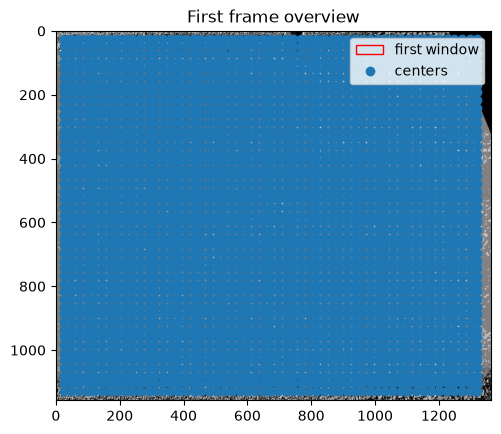

In [7]:
# plot image with measurement grid
ax = plt.axes()

# plot the first image with a patch at the first window and centers of rest in the first axes instance
win = np.int_(iw.windows.shape[0]/2)
xi, yi = np.meshgrid(iw.x, iw.y)
x_patch = np.int_(xi.flatten()[win]) - np.int_(win_size[0] / 2)
y_patch = np.int_(yi.flatten()[win]) - np.int_(win_size[1] / 2)
first_window = patches.Rectangle((x_patch, y_patch), win_size[0], win_size[1], linewidth=1, edgecolor='r', facecolor='none', label="first window")

ax.imshow(iw.imgs[0], cmap="Greys_r")
ax.add_patch(first_window)
ax.plot(xi.flatten(), yi.flatten(), "o", label="centers")
ax.legend()
ax.set_title("First frame overview")

# plt.savefig(f"{savepath}\\plots\\{filename}_measurement_points.png")
# plt.savefig(f"{savepath}\\plots\\{filename}_measurement_points.eps")
plt.show()

In [8]:
# calculate velocities
iw.velocimetry(
    alpha=0.85,  # alpha represents the depth-averaged velocity over surface velocity [-]
)

Optimization in 2 steps with spectrum downsampling factor [2, 1]


Optimizing windows: 100%|██████████| 2585/2585 [28:55<00:00,  1.49it/s] 


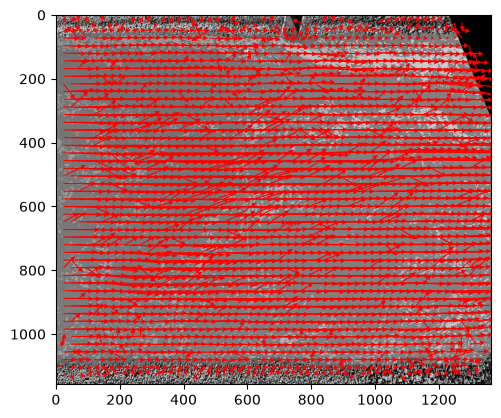

In [9]:
ax = plt.axes()
ax.imshow(iw.imgs[0], cmap="Greys_r")

# add velocity vectors
iw.plot_velocimetry(ax=ax, color="r", scale=10, headwidth=5, linewidth=5)  # you can add kwargs that belong to matplotlib.pyploy.quiver
# plt.savefig(f"{savepath}\\plots\\{filename}_quiver.png")
# plt.savefig(f"{savepath}\\plots\\{filename}_quiver.eps")
plt.show()

In [10]:
ux, uy, d, q = iw.vx, iw.vy, iw.d, iw.quality
u = np.sqrt(ux**2 + uy**2)

In [11]:
# transect_axs=iw.plot_transect(column=15)
# plt.show()

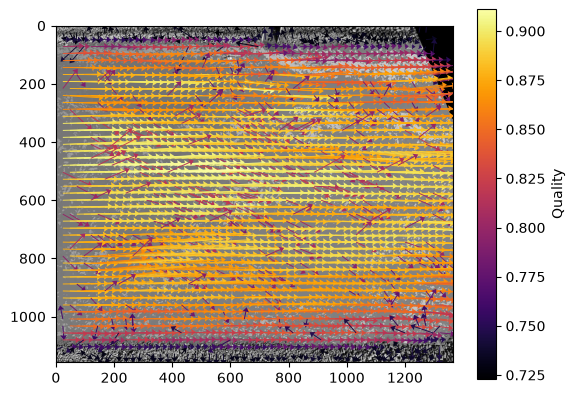

In [12]:
ax = plt.axes()
ax.imshow(iw.imgs[0], cmap="Greys_r")

quiv = ax.quiver(
    xi, yi, ux, uy,
    q,                          
    angles="xy", scale=7, headwidth=7, linewidth=7,
    cmap="inferno"              
)

cbar = plt.colorbar(quiv, ax=ax)
cbar.set_label("Quality")

ax.set_aspect("equal")
# plt.savefig(f"{savepath}\\plots\\{filename}_quiver_quality.png")
# plt.savefig(f"{savepath}\\plots\\{filename}_quiver_quality.eps")
plt.show()

In [13]:
# load and attribute coordinates to points
coord = pd.read_csv(coordpath) # coordinates of each pixel in images
img_size = iw.imgs[0].shape
img_size_y = img_size[0]+1
img_size_x = img_size[1]

# reshape coordinates
x_mat = coord['x'].to_numpy().reshape(img_size_x,img_size_y)
y_mat = coord['y'].to_numpy().reshape(img_size_x,img_size_y)
xs_mat = coord['xs'].to_numpy().reshape(img_size_x,img_size_y)
ys_mat = coord['ys'].to_numpy().reshape(img_size_x,img_size_y)
lon_mat = coord['lon'].to_numpy().reshape(img_size_x,img_size_y)
lat_mat = coord['lat'].to_numpy().reshape(img_size_x,img_size_y)

# extract measurement points
# round indices
xi, yi = np.meshgrid(np.int_(iw.x), np.int_(iw.y))

# extract coordinates
xm = x_mat[xi, yi]  
ym = y_mat[xi, yi]  
xs = xs_mat[xi, yi]  
ys = ys_mat[xi, yi]  
lon = lon_mat[xi, yi]  
lat = lat_mat[xi, yi]  

C:\Users\gdolc\AppData\Local\Temp\ipykernel_28108\1079384282.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend()
C:\Users\gdolc\AppData\Local\Temp\ipykernel_28108\1079384282.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[1].legend()
C:\Users\gdolc\AppData\Local\Temp\ipykernel_28108\1079384282.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2].legend()


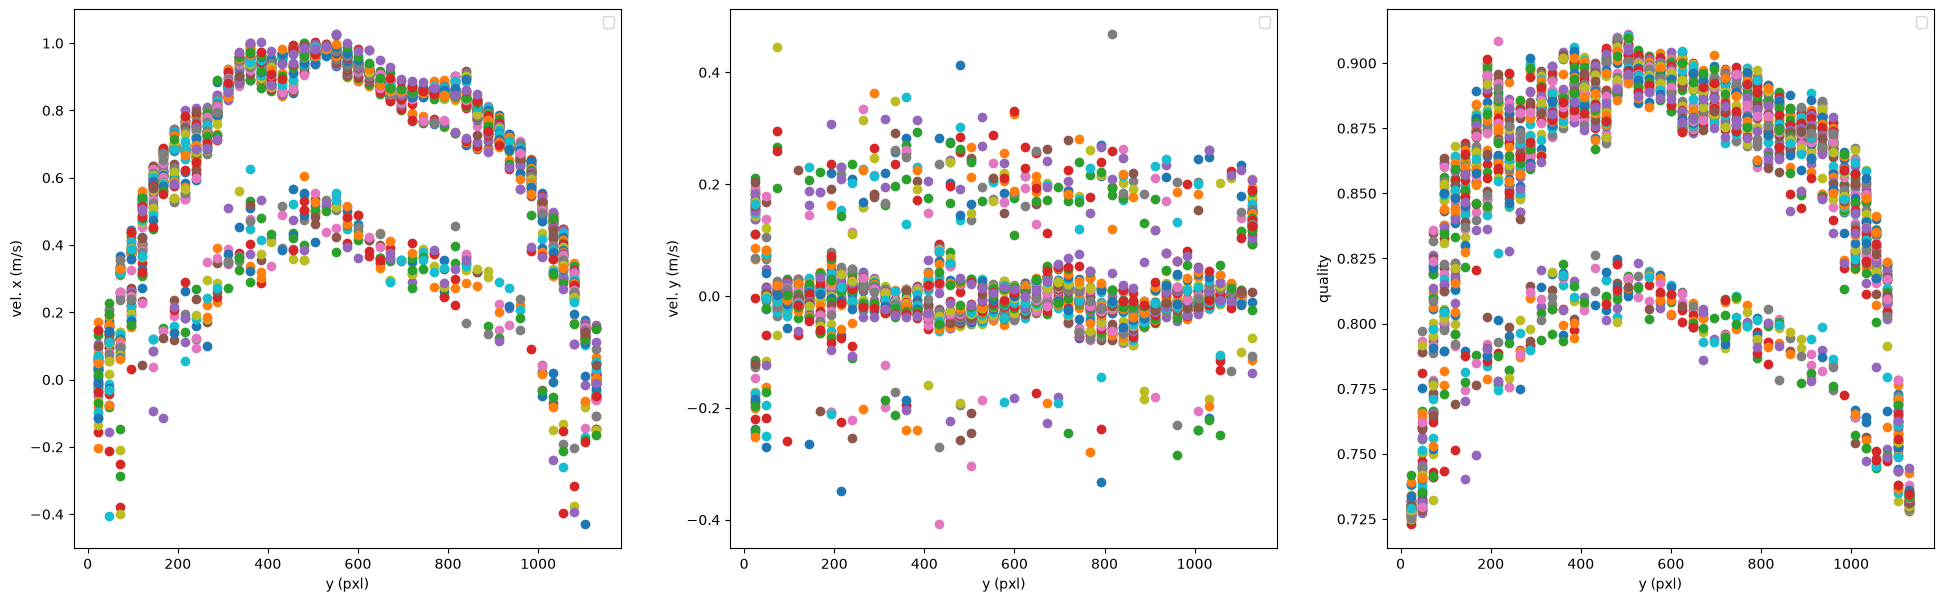

In [14]:
# plot velocity transects (spatial coordinates in pixels)

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(24, 7))

for j in range(ux.shape[1]):
    axs[0].plot(yi[:,j].flatten(),ux[:,j].flatten(), 'o')
axs[0].set_xlabel('y (pxl)')
axs[0].set_ylabel('vel. x (m/s)')
axs[0].legend()

for j in range(uy.shape[1]):
    axs[1].plot(yi[:,j].flatten(),uy[:,j].flatten(), 'o')
axs[1].set_xlabel('y (pxl)')
axs[1].set_ylabel('vel. y (m/s)')
axs[1].legend()

for j in range(q.shape[1]):
    axs[2].plot(yi[:,j].flatten(),q[:,j].flatten(), 'o')
axs[2].set_xlabel('y (pxl)')
axs[2].set_ylabel('quality')
axs[2].legend()


# Display the plot
# plt.savefig(f"{savepath}\\plots\\{filename}_results.png")
# plt.savefig(f"{savepath}\\plots\\{filename}_results.eps")
plt.show()

windows: [1738 2566 1624 1945]


c:\Users\gdolc\_python\faster-optimisation\IWaVE\iwave\io.py:251: RuntimeWarning: divide by zero encountered in log
  imvals = np.log(imvals)


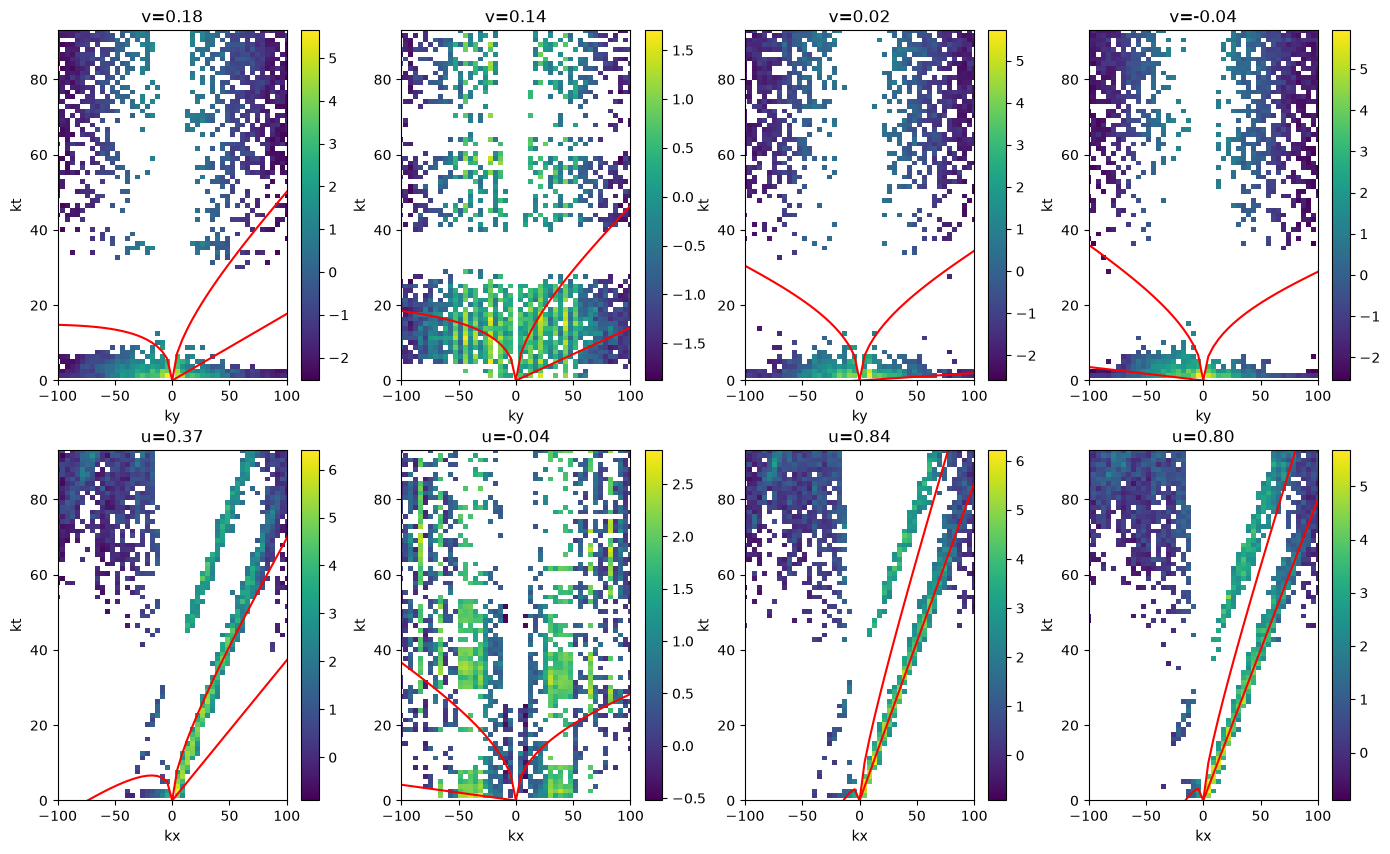

In [15]:
# pick 4 random windows
w_indices = np.random.randint(0, iw.windows.shape[0], size=4)
# w_indices = np.round((np.arange(1, 4) * iw.windows.shape[0] / 4)).astype(int)

print(f"windows: {w_indices}")
fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(17, 10))
axs = axs.flatten()
for i in range(len(w_indices)):
    p1 = iw.plot_spectrum_fitted(window_idx=int(w_indices[i]), dim="x", ax=axs[i])
    axs[i].set_title(f"v={iw.vy.flatten()[w_indices[i]].item():.2f}")
    axs[i].set_xlim([-100, 100])
    plt.colorbar(p1, ax=axs[i])
    p2 = iw.plot_spectrum_fitted(window_idx=int(w_indices[i]), dim="y", ax=axs[i+4])
    axs[i+4].set_title(f"u={iw.vx.flatten()[w_indices[i]].item():.2f}")
    axs[i+4].set_xlim([-100, 100])
    plt.colorbar(p2, ax=axs[i+4])
    
# plt.savefig(f"{savepath}\\plots\\{filename}_spectra.png")
# plt.savefig(f"{savepath}\\plots\\{filename}_spectra.eps")
plt.show()

In [16]:
# Save results to netCDF file
# with nc.Dataset(f'{savepath}\\results\\{filename}_IWaVE.nc', 'w', format='NETCDF4') as ds:
#     ds.createDimension('x', xi.shape[1])
#     ds.createDimension('y', xi.shape[0])

#     # pixel coordinates
#     xi_var = ds.createVariable('xi', 'f4', ('y', 'x'))
#     yi_var = ds.createVariable('yi', 'f4', ('y', 'x'))
    
#     xi_var[:, :] = xi
#     yi_var[:, :] = yi

#     # velocities and quality
#     vx_var = ds.createVariable('vx', 'f4', ('y', 'x'))
#     vy_var = ds.createVariable('vy', 'f4', ('y', 'x'))
#     q_var = ds.createVariable('q', 'f4', ('y', 'x'))
    
#     vx_var[:, :] = ux
#     vy_var[:, :] = uy
#     q_var[:, :] = q

#     # georeferencing coordinates
#     xm_var = ds.createVariable('xm', 'f4', ('y', 'x'))
#     ym_var = ds.createVariable('ym', 'f4', ('y', 'x'))
#     xs_var = ds.createVariable('xs', 'f4', ('y', 'x'))
#     ys_var = ds.createVariable('ys', 'f4', ('y', 'x'))
#     lon_var = ds.createVariable('lon', 'f4', ('y', 'x'))
#     lat_var = ds.createVariable('lat', 'f4', ('y', 'x'))

#     xm_var[:, :] = xm
#     ym_var[:, :] = ym
#     xs_var[:, :] = xs
#     ys_var[:, :] = ys
#     lon_var[:, :] = lon
#     lat_var[:, :] = lat

In [17]:
# Save results to csv file

# xi_flat = xi.flatten()
# yi_flat = yi.flatten()
# vx_flat = ux.flatten()
# vy_flat = uy.flatten()
# q_flat = q.flatten()

# #georeferencing coordinates
# xm_flat = xm.flatten()
# ym_flat = ym.flatten()
# xs_flat = xs.flatten()
# ys_flat = ys.flatten()
# lon_flat = lon.flatten()
# lat_flat = lat.flatten()

# # with georeferencing
# df = pd.DataFrame({'x': xi_flat, 'y': yi_flat, 'vx': vx_flat, 'vy': vy_flat, 'q': q_flat, 'xm': xm_flat, 'ym': ym_flat, 'xs': xs_flat, 'ys': ys_flat, 'lon': lon_flat, 'lat': lat_flat})

# # without georeferencing
# # df = pd.DataFrame({'x': xi_flat, 'y': yi_flat, 'vx': vx_flat, 'vy': vy_flat, 'q': q_flat})

# df.to_csv(f'{savepath}\\results\\{filename}_IWaVE.csv', index=False)